# CoKriging Nested Design Spot Check (2D)

Variant of `CoKriging_2DSpotCheck.ipynb` where the HF samples are a **subset of the LF samples** (a nested design), instead of being drawn independently. The LF samples and test points are unchanged, so only the HF locations differ.

`CoKriging` is not modified. It fits in the same two stages:
1. **LF fit:** a `Kriging` model is fit to the LF samples.
2. **MF fit:** a `DiffKriging` model is fit to `y_hf - rho * y_lf(x)` at the HF samples, with `rho` optimized alongside its other hyperparameters. The two models are then combined in a block covariance matrix.

`y_lf(x)` still comes from the LF Kriging model rather than the LF samples themselves. With a nested design the HF points are LF training points, so the two differ only by the nugget's smoothing.

The HF subset is chosen by greedy maximin: starting from the first LF sample, repeatedly add the LF sample farthest from those already chosen. This spreads the HF points out and tends to pick boundary points early.

As a baseline, an **HF-only fit** trains a separate `Kriging` model on the same HF samples, with the same nugget. The seed check at the end compares the nested and independent designs over several sample sets.

With `scale_input=True`, `x` is scaled to [-1, 1] using the function's bounds. Neither model scales its outputs, so all errors here are in original units.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from SurrogateModels import cokriging, kriging

### Data

In [2]:
def nested_subset(X, n, bounds):
    """Select n rows of X by greedy maximin, in coordinates scaled to the unit box."""
    bounds = np.asarray(bounds)
    X_unit = (X - bounds[:, 0]) / (bounds[:, 1] - bounds[:, 0])
    chosen = [0]
    min_dist = np.linalg.norm(X_unit - X_unit[0], axis=1)
    for _ in range(n - 1):
        chosen.append(int(np.argmax(min_dist)))
        min_dist = np.minimum(min_dist, np.linalg.norm(X_unit - X_unit[chosen[-1]], axis=1))
    return X[chosen]


key = "2D"
my_function = mfs.increasing_dimensions[key]()

n_lf = 400
n_hf = 100
seed = 0

X_lf = my_function.sample_random(n_lf, seed=seed)
y_lf = my_function.low_fidelity(X_lf)
X_hf = nested_subset(X_lf, n_hf, my_function.bounds)
y_hf = my_function.high_fidelity(X_hf)

# Shared test locations, evaluated with each fidelity
X_test = my_function.sample_random(1000, seed=1234)
y_lf_test = my_function.low_fidelity(X_test)
y_hf_test = my_function.high_fidelity(X_test)

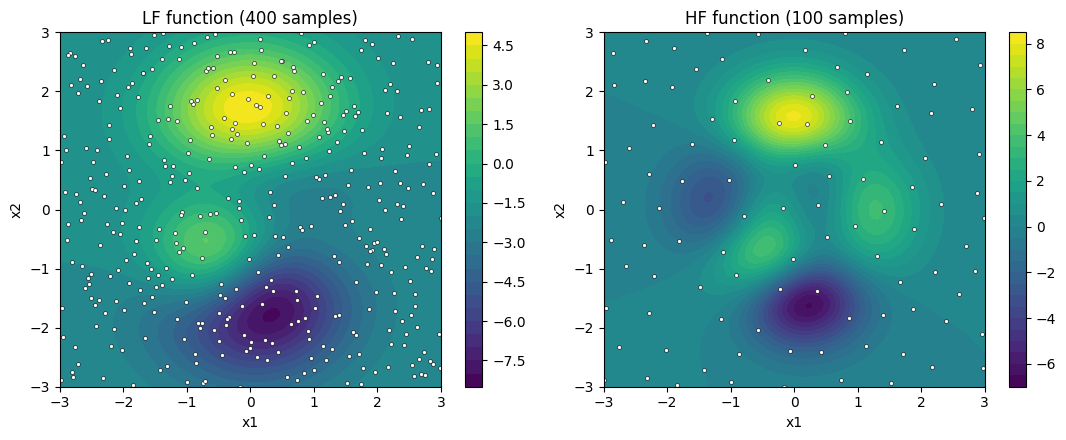

In [3]:
# Contour grid over the function's bounds, reused for all plots below
n_grid = 100
(x1_min, x1_max), (x2_min, x2_max) = my_function.bounds
X1, X2 = np.meshgrid(np.linspace(x1_min, x1_max, n_grid), np.linspace(x2_min, x2_max, n_grid))
X_grid = np.column_stack([X1.ravel(), X2.ravel()])
y_lf_grid = my_function.low_fidelity(X_grid).reshape(n_grid, n_grid)
y_hf_grid = my_function.high_fidelity(X_grid).reshape(n_grid, n_grid)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, Z, X_s, title in [
    (axes[0], y_lf_grid, X_lf, f"LF function ({n_lf} samples)"),
    (axes[1], y_hf_grid, X_hf, f"HF function ({n_hf} samples)"),
]:
    cs = ax.contourf(X1, X2, Z, levels=30, cmap="viridis")
    ax.scatter(X_s[:, 0], X_s[:, 1], s=8, color="white", edgecolor="black", linewidth=0.4)
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    fig.colorbar(cs, ax=ax)
plt.tight_layout()
plt.show()

### Train

In [4]:
settings = dict(
    nugget=1e-3,
    scale_input=True,
    bounds=my_function.bounds,
)

ck_model = cokriging.CoKriging(X_lf, y_lf, X_hf, y_hf, **settings)

# The internal LF model was fit on scaled x and doesn't scale its own inputs,
# so it has to be given scaled x
lf_kriging = ck_model.kriging_lf
diff_kriging = ck_model.kriging_diff
lf_error = float(lf_kriging.model_error(ck_model.x_scale.transform(X_test), y_lf_test))
mf_error = float(ck_model.model_error(X_test, y_hf_test))
print(f"Train time: {ck_model.training_time:.1f}s")
print(f"LF fit test RMSE (vs LF function): {lf_error:.4g}")
print(f"MF fit test RMSE (vs HF function): {mf_error:.4g}")

Train time: 35.9s
LF fit test RMSE (vs LF function): 0.003138
MF fit test RMSE (vs HF function): 0.1056


In [5]:
# HF-only baseline: same nugget and scaling, fit on the HF samples alone
hf_kriging = kriging.Kriging(X_hf, y_hf, **settings)

hf_error = float(hf_kriging.model_error(X_test, y_hf_test))
print(f"Train time: {hf_kriging.training_time:.1f}s")
print(f"HF-only fit test RMSE (vs HF function): {hf_error:.4g}")
print(f"MF fit test RMSE (vs HF function):      {mf_error:.4g}")

Train time: 3.7s
HF-only fit test RMSE (vs HF function): 0.0946
MF fit test RMSE (vs HF function):      0.1056


### Hyperparameters

Kriging has no training history, so this replaces the convergence plots of the NN notebook. `theta` is per input, on scaled `x`, and larger values mean the function varies faster along that input. The optimizer limits `theta` to [1e-3, 1e3], so a value at either limit means the fit is constrained. `sigma2` is the process variance, and `rho` scales the LF model in the MF fit.

In [6]:
for name, fit in [("LF", lf_kriging), ("Difference", diff_kriging), ("HF-only", hf_kriging)]:
    print(
        f"{name}: theta {np.round(fit.theta, 3)}, p {np.round(fit.p, 3)}, "
        f"sigma2 {fit.sigma.item():.4g}"
    )
print(f"rho: {diff_kriging.scale_factor:.4g}")

LF: theta [6.121 7.265], p [2. 2.], sigma2 0.3381
Difference: theta [10.507  8.227], p [2.    1.956], sigma2 1.29
HF-only: theta [8.909 9.186], p [2. 2.], sigma2 2.854
rho: 0.9516


### Fit quality

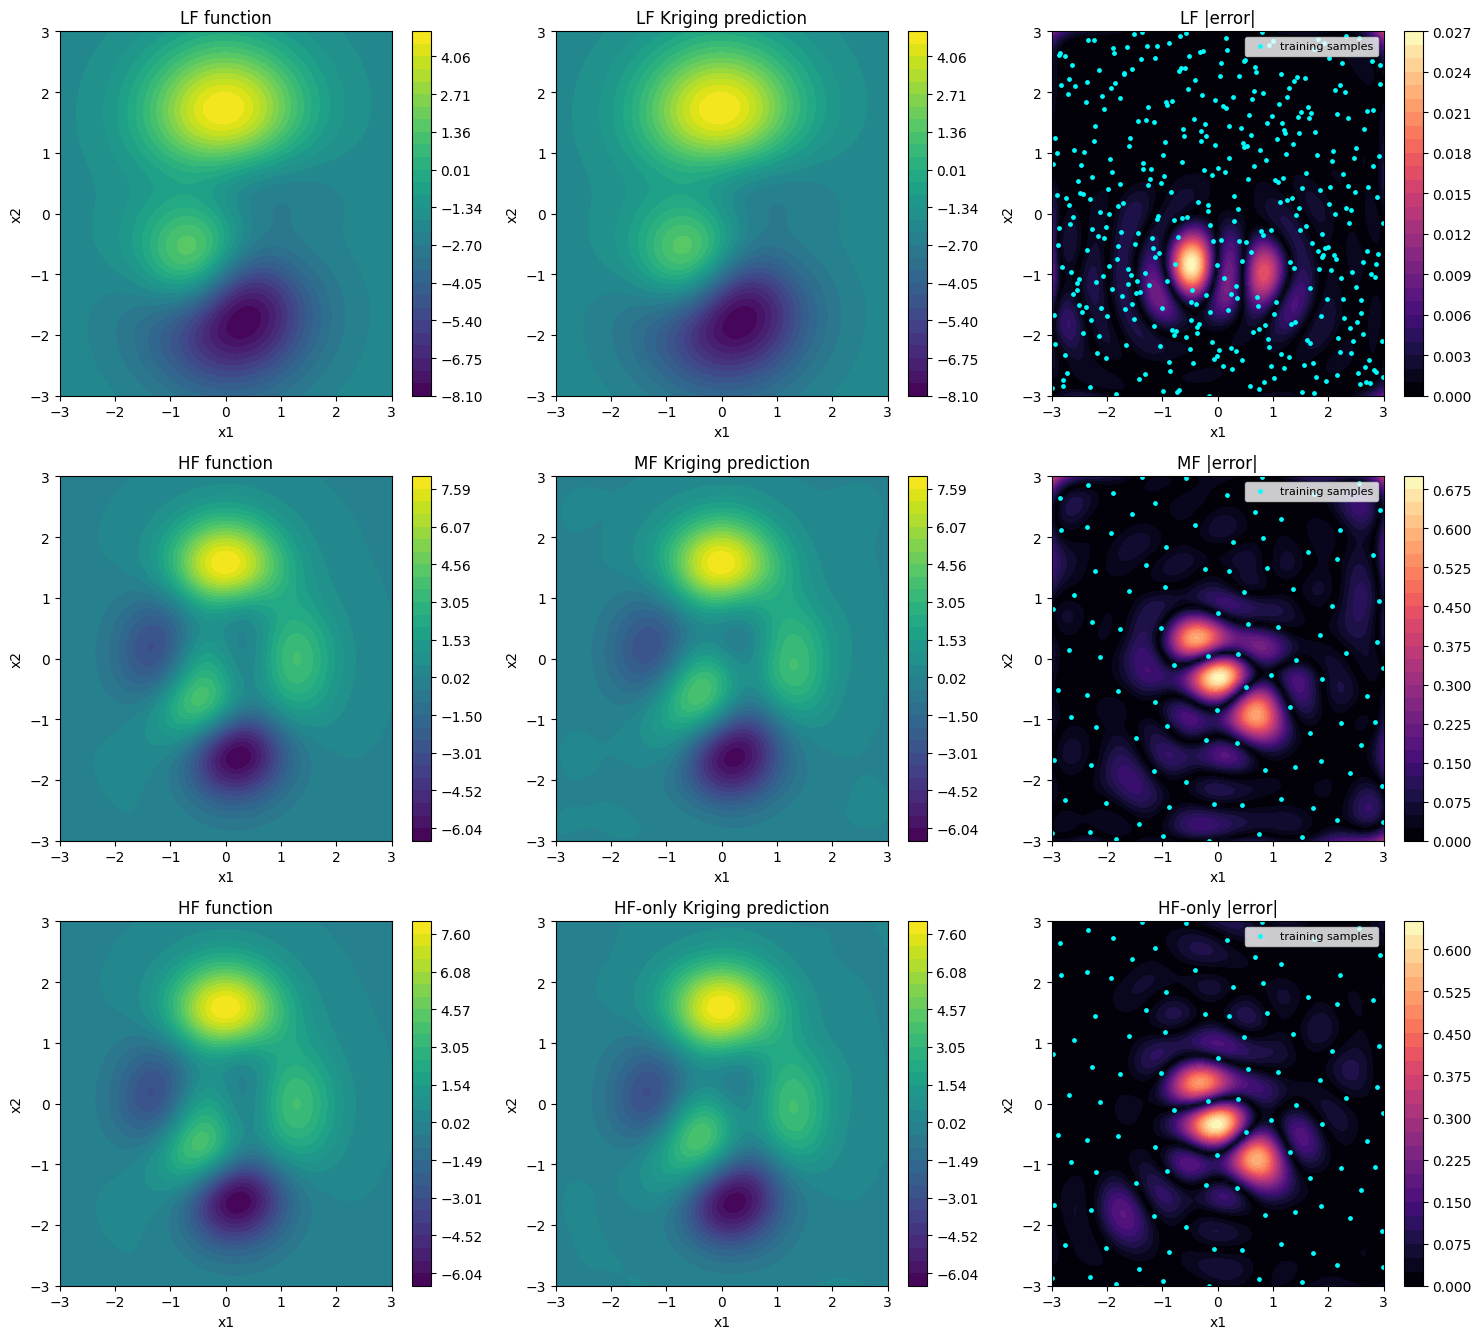

In [7]:
y_lf_hat_grid = lf_kriging.evaluate(ck_model.x_scale.transform(X_grid)).reshape(n_grid, n_grid)
y_mf_hat_grid = ck_model.evaluate(X_grid).reshape(n_grid, n_grid)
y_hf_hat_grid = hf_kriging.evaluate(X_grid).reshape(n_grid, n_grid)

rows = [
    ("LF", y_lf_grid, y_lf_hat_grid, X_lf),
    ("MF", y_hf_grid, y_mf_hat_grid, X_hf),
    ("HF-only", y_hf_grid, y_hf_hat_grid, X_hf),
]
fig, axes = plt.subplots(3, 3, figsize=(15, 13.5))
for row, (name, Z_true, Z_hat, X_s) in zip(axes, rows):
    levels = np.linspace(min(Z_true.min(), Z_hat.min()), max(Z_true.max(), Z_hat.max()), 30)
    target = "LF" if name == "LF" else "HF"
    for ax, Z, title in [
        (row[0], Z_true, f"{target} function"),
        (row[1], Z_hat, f"{name} Kriging prediction"),
    ]:
        cs = ax.contourf(X1, X2, Z, levels=levels, cmap="viridis")
        fig.colorbar(cs, ax=ax)
        ax.set_title(title)
    cs = row[2].contourf(X1, X2, np.abs(Z_hat - Z_true), levels=30, cmap="magma")
    row[2].scatter(X_s[:, 0], X_s[:, 1], s=6, color="cyan", label="training samples")
    fig.colorbar(cs, ax=row[2])
    row[2].set_title(f"{name} |error|")
    row[2].legend(loc="upper right", fontsize=8)
    for ax in row:
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
plt.tight_layout()
plt.show()

### Seed check

Repeats both fits over several sample sets, for the independent design of `CoKriging_2DSpotCheck.ipynb` and the nested design. Each sample set shares one LF fit between the two designs, since the LF samples are the same. Edge test points are those in the outer 10% of either axis, and the errors are test RMSE against the HF function.

In [8]:
n_seeds = 5

bounds = np.asarray(my_function.bounds)
X_test_unit = (X_test - bounds[:, 0]) / (bounds[:, 1] - bounds[:, 0])
edge = np.abs(2 * X_test_unit - 1).max(axis=1) > 0.8


def split_rmse(fit):
    sq_error = (fit.evaluate(X_test) - y_hf_test) ** 2
    return [np.sqrt(sq_error[mask].mean()) for mask in (np.ones_like(edge), edge, ~edge)]


results = {}
for s in range(n_seeds):
    X_lf_s = my_function.sample_random(n_lf, seed=s)
    y_lf_s = my_function.low_fidelity(X_lf_s)
    lf_fit = None
    for design, X_hf_s in [
        ("Independent", my_function.sample_random(n_hf, seed=s)),
        ("Nested", nested_subset(X_lf_s, n_hf, my_function.bounds)),
    ]:
        y_hf_s = my_function.high_fidelity(X_hf_s)
        ck_fit = cokriging.CoKriging(
            X_lf_s, y_lf_s, X_hf_s, y_hf_s, lf_kriging_model=lf_fit, **settings
        )
        lf_fit = ck_fit.kriging_lf
        hf_fit = kriging.Kriging(X_hf_s, y_hf_s, **settings)
        results.setdefault((design, "CoKriging"), []).append(split_rmse(ck_fit))
        results.setdefault((design, "HF-only"), []).append(split_rmse(hf_fit))

print(f"{'Design':<12} {'Model':<10} {'All':>7} {'Edge':>7} {'Interior':>9}")
for (design, name), rmse in results.items():
    all_rmse, edge_rmse, interior_rmse = np.mean(rmse, axis=0)
    print(f"{design:<12} {name:<10} {all_rmse:7.4f} {edge_rmse:7.4f} {interior_rmse:9.4f}")

for design in ["Independent", "Nested"]:
    ck_all = np.array(results[design, "CoKriging"])[:, 0]
    hf_all = np.array(results[design, "HF-only"])[:, 0]
    print(f"{design}: CoKriging beats HF-only on {(ck_all < hf_all).sum()} of {n_seeds} seeds")
    print(f"  CoKriging by seed: {np.round(ck_all, 4)}")
    print(f"  HF-only by seed:   {np.round(hf_all, 4)}")

Design       Model          All    Edge  Interior
Independent  CoKriging   0.1696  0.2095    0.1388
Independent  HF-only     0.1206  0.0580    0.1432
Nested       CoKriging   0.0771  0.0640    0.0823
Nested       HF-only     0.0695  0.0354    0.0818
Independent: CoKriging beats HF-only on 0 of 5 seeds
  CoKriging by seed: [0.1751 0.1346 0.2313 0.1487 0.1584]
  HF-only by seed:   [0.1255 0.1058 0.114  0.1127 0.1451]
Nested: CoKriging beats HF-only on 1 of 5 seeds
  CoKriging by seed: [0.1056 0.0738 0.0746 0.0679 0.0634]
  HF-only by seed:   [0.0946 0.0649 0.0562 0.0761 0.0559]
